In [1]:
from piano2midi.evaluation.metrics import (
    evaluate_note_set,
    evaluate_matched_offsets,
    evaluate_notes,
)

truth = [
    {"pitch": 60, "onset": 1.0, "offset": 2.0},
]

predicted = [
    {"pitch": 60, "onset": 1.01, "offset": 1.70},
]

detection = evaluate_note_set(truth, predicted)
offsets = evaluate_matched_offsets(
    truth, predicted, detection["matches"]
)
strict = evaluate_notes(truth, predicted)

print("Detection:", detection)
print("Offsets:", offsets)
print("Strict:", strict)

Detection: {'TP': 1, 'FP': 0, 'FN': 0, 'precision': 1.0, 'recall': 1.0, 'F1': 1.0, 'matches': [(0, 0)]}
Offsets: {'matched_notes': 1, 'mean_absolute_offset_error': 0.30000000000000004}
Strict: {'TP': 0, 'FP': 1, 'FN': 1, 'precision': 0.0, 'recall': 0.0, 'F1': 0.0}


In [2]:
from pathlib import Path

p = Path.cwd()

while p != p.parent and not (p / "scripts" / "benchmark_transkun.py").is_file():
    p = p.parent

if not (p / "scripts" / "benchmark_transkun.py").is_file():
    raise FileNotFoundError("Could not locate the project root")

project_root = p
print("Project root:", project_root)

Project root: c:\Users\Deep\Desktop\Deep\Piano2MIDI\piano2midi


In [3]:
benchmark_path = project_root / "scripts" / "benchmark_transkun.py"
print("Benchmark exists:", benchmark_path.is_file())
print(benchmark_path)

Benchmark exists: True
c:\Users\Deep\Desktop\Deep\Piano2MIDI\piano2midi\scripts\benchmark_transkun.py


In [4]:
import importlib.util

benchmark_path = project_root / "scripts" / "benchmark_transkun.py"

spec = importlib.util.spec_from_file_location(
    "benchmark_transkun", benchmark_path
)
benchmark = importlib.util.module_from_spec(spec)
spec.loader.exec_module(benchmark)

notes = benchmark.midi_to_notes(
    project_root / "data" / "raw" / "maestro" / "piano_sample.midi"
)

print("Reference notes:", len(notes))
print("First 5 notes:")
for note in notes[:5]:
    print(note)

Reference notes: 17876
First 5 notes:
{'pitch': 42, 'onset': 1.0494791666666665, 'offset': 1.7174479166666663}
{'pitch': 49, 'onset': 1.6249999999999996, 'offset': 2.0624999999999996}
{'pitch': 57, 'onset': 2.018229166666666, 'offset': 2.1718749999999996}
{'pitch': 57, 'onset': 2.2968749999999996, 'offset': 2.498697916666666}
{'pitch': 49, 'onset': 2.5052083333333326, 'offset': 2.7265624999999996}


In [5]:
from piano2midi.evaluation.metrics import (
    evaluate_notes,
    evaluate_note_set,
    evaluate_matched_offsets,
)

prediction_path = project_root / "data" / "processed" / "piano_sample_20s.mid"
reference_path = project_root / "data" / "raw" / "maestro" / "piano_sample.midi"

predictions = benchmark.midi_to_notes(prediction_path)
ground_truth = benchmark.midi_to_notes(reference_path)

# Restrict both sets to the 20-second excerpt.
ground_truth = [n for n in ground_truth if n["onset"] < 20.0]
predictions = [n for n in predictions if n["onset"] < 20.0]

note_set = evaluate_note_set(ground_truth, predictions)
offsets = evaluate_matched_offsets(
    ground_truth, predictions, note_set["matches"]
)
strict = evaluate_notes(ground_truth, predictions)

print("Reference notes:", len(ground_truth))
print("Predicted notes:", len(predictions))
print("\nNote-set metrics:", {k: v for k, v in note_set.items() if k != "matches"})
print("Offset metrics:", offsets)
print("Strict metrics:", strict)

Reference notes: 97
Predicted notes: 95

Note-set metrics: {'TP': 95, 'FP': 0, 'FN': 2, 'precision': 1.0, 'recall': 0.979381443298969, 'F1': 0.9895833333333333}
Offset metrics: {'matched_notes': 95, 'mean_absolute_offset_error': 0.10513432017543793}
Strict metrics: {'TP': 76, 'FP': 19, 'FN': 21, 'precision': 0.8, 'recall': 0.7835051546391752, 'F1': 0.7916666666666666}


In [6]:
# Inspect offset errors for notes matched by pitch and onset.
offset_errors = sorted(
    abs(
        ground_truth[true_idx]["offset"]
        - predictions[pred_idx]["offset"]
    )
    for true_idx, pred_idx in note_set["matches"]
)

within_50ms = sum(error <= 0.05 for error in offset_errors)

print("Matched notes:", len(offset_errors))
print("Offset errors <= 50 ms:", within_50ms)
print("Offset errors > 50 ms:", len(offset_errors) - within_50ms)
print("Median offset error (ms):", offset_errors[len(offset_errors)//2] * 1000)
print("90th percentile offset error (ms):", offset_errors[int(0.9 * (len(offset_errors)-1))] * 1000)

print("\nLargest 5 offset errors (ms):")
for error in offset_errors[-5:]:
    print(round(error * 1000, 2))

Matched notes: 95
Offset errors <= 50 ms: 76
Offset errors > 50 ms: 19
Median offset error (ms): 19.531249999982236
90th percentile offset error (ms): 200.52083333331083

Largest 5 offset errors (ms):
869.01
1032.81
1348.7
1474.74
1491.93


In [7]:
bad_offsets = []

for true_idx, pred_idx in note_set["matches"]:
    true_note = ground_truth[true_idx]
    pred_note = predictions[pred_idx]

    error = abs(true_note["offset"] - pred_note["offset"])

    if error > 0.05:
        bad_offsets.append({
            "pitch": true_note["pitch"],
            "true_onset": true_note["onset"],
            "pred_onset": pred_note["onset"],
            "true_offset": true_note["offset"],
            "pred_offset": pred_note["offset"],
            "offset_error_ms": error * 1000,
        })

for note in sorted(
    bad_offsets,
    key=lambda n: n["offset_error_ms"],
    reverse=True,
):
    print(note)

{'pitch': 54, 'true_onset': 10.423177083333337, 'pred_onset': 10.419270833333336, 'true_offset': 10.894531250000005, 'pred_offset': 12.386458333333335, 'offset_error_ms': 1491.92708333333}
{'pitch': 57, 'true_onset': 8.221354166666668, 'pred_onset': 8.215104166666665, 'true_offset': 10.402343750000004, 'pred_offset': 8.927604166666667, 'offset_error_ms': 1474.7395833333367}
{'pitch': 69, 'true_onset': 18.41536458333332, 'pred_onset': 18.417708333333337, 'true_offset': 20.214843749999986, 'pred_offset': 18.866145833333338, 'offset_error_ms': 1348.6979166666479}
{'pitch': 59, 'true_onset': 19.29036458333332, 'pred_onset': 19.285416666666674, 'true_offset': 19.41145833333332, 'pred_offset': 20.44427083333334, 'offset_error_ms': 1032.81250000002}
{'pitch': 42, 'true_onset': 1.0494791666666665, 'pred_onset': 1.0515625, 'true_offset': 1.7174479166666663, 'pred_offset': 2.5864583333333337, 'offset_error_ms': 869.0104166666674}
{'pitch': 42, 'true_onset': 8.247395833333334, 'pred_onset': 8.236

In [8]:
from pathlib import Path

processed_dir = project_root / "data" / "processed"

for path in sorted(processed_dir.iterdir()):
    if "happy_bday" in path.name.lower():
        print(
            f"{path.name:40} "
            f"{path.suffix:10} "
            f"{path.stat().st_size / 1024:.1f} KB"
        )

happy_bday.mp3                           .mp3       894.0 KB
happy_bday_midi.mid                      .mid       0.7 KB


In [9]:
ordered = sorted(notes, key=lambda n: n["onset"])
groups = []
tolerance = 0.03  # 30 milliseconds

for note in ordered:
    if (
        not groups
        or note["onset"] - groups[-1][0]["onset"] > tolerance
    ):
        groups.append([note])
    else:
        groups[-1].append(note)

simultaneous = [g for g in groups if len(g) > 1]

print("Groups with onsets within 30 ms:", len(simultaneous))

for group in simultaneous:
    print(
        f'{group[0]["onset"]:.3f}s:',
        [
            {
                "pitch": n["pitch"],
                "offset": round(n["offset"], 3),
                "duration": round(n["offset"] - n["onset"], 3),
            }
            for n in group
        ],
    )

Groups with onsets within 30 ms: 4556
3.767s: [{'pitch': 66, 'offset': 5.94, 'duration': 2.173}, {'pitch': 42, 'offset': 4.488, 'duration': 0.716}]
6.079s: [{'pitch': 62, 'offset': 8.165, 'duration': 2.086}, {'pitch': 42, 'offset': 6.648, 'duration': 0.553}]
8.221s: [{'pitch': 57, 'offset': 10.402, 'duration': 2.181}, {'pitch': 42, 'offset': 8.715, 'duration': 0.467}]
10.423s: [{'pitch': 54, 'offset': 10.895, 'duration': 0.471}, {'pitch': 42, 'offset': 10.908, 'duration': 0.464}]
14.513s: [{'pitch': 68, 'offset': 16.536, 'duration': 2.023}, {'pitch': 42, 'offset': 15.003, 'duration': 0.474}]
16.858s: [{'pitch': 61, 'offset': 20.335, 'duration': 3.477}, {'pitch': 42, 'offset': 17.199, 'duration': 0.332}]
18.573s: [{'pitch': 42, 'offset': 19.001, 'duration': 0.428}, {'pitch': 71, 'offset': 20.18, 'duration': 1.607}]
20.622s: [{'pitch': 61, 'offset': 23.134, 'duration': 2.512}, {'pitch': 42, 'offset': 20.891, 'duration': 0.263}]
22.182s: [{'pitch': 74, 'offset': 23.335, 'duration': 1.152}

In [10]:

notes = sorted(
    benchmark.midi_to_notes(
        project_root / "data" / "processed" / "happy_bday_midi.mid"
    ),
    key=lambda n: n["onset"]
)

print(f"Total notes: {len(notes)}\n")
print(f"{'Onset':>8} {'Offset':>8} {'Pitch':>6} {'Duration':>9}")
print("-" * 36)

for n in notes:
    onset = n["onset"]
    if 8 <= onset <= 12 or 28 <= onset <= 33:
        duration = n["offset"] - onset
        print(
            f"{onset:8.3f} {n['offset']:8.3f} "
            f"{n['pitch']:6} {duration:9.3f}"
        )


Total notes: 88

   Onset   Offset  Pitch  Duration
------------------------------------
   8.634   11.574     38     2.941
   8.641   11.692     65     3.051
   8.642   10.878     71     2.236
   8.642   11.737     60     3.095
   8.645   11.714     62     3.069
   8.645   11.574     57     2.929
  10.851   11.552     67     0.701
  11.690   11.971     67     0.281
  11.951   15.290     31     3.339
  11.961   13.109     69     1.148
  11.963   13.130     62     1.167
  11.963   13.711     55     1.748
  11.965   13.781     59     1.816
  28.961   32.868     72     3.907
  28.961   32.982     55     4.021
  28.962   32.798     60     3.835
  28.964   32.961     64     3.997
  28.966   32.938     36     3.972


In [11]:

from collections import Counter

print("Pitch counts (MIDI pitch: number of notes):")
print(sorted(Counter(n["pitch"] for n in notes).items()))

print("\nLongest 12 notes:")
for n in sorted(
    notes,
    key=lambda n: n["offset"] - n["onset"],
    reverse=True
)[:12]:
    print(
        f"pitch={n['pitch']:3}, "
        f"onset={n['onset']:7.3f}s, "
        f"offset={n['offset']:7.3f}s, "
        f"duration={n['offset'] - n['onset']:6.3f}s"
    )


Pitch counts (MIDI pitch: number of notes):
[(31, 1), (36, 2), (38, 1), (40, 2), (41, 1), (42, 1), (43, 3), (48, 2), (53, 1), (55, 6), (57, 2), (59, 3), (60, 10), (62, 5), (64, 9), (65, 3), (67, 13), (69, 5), (70, 1), (71, 2), (72, 8), (74, 2), (76, 2), (77, 2), (79, 1)]

Longest 12 notes:
pitch= 55, onset= 28.961s, offset= 32.982s, duration= 4.021s
pitch= 64, onset= 28.964s, offset= 32.961s, duration= 3.997s
pitch= 36, onset= 28.966s, offset= 32.938s, duration= 3.972s
pitch= 72, onset= 28.961s, offset= 32.868s, duration= 3.907s
pitch= 60, onset= 28.962s, offset= 32.798s, duration= 3.835s
pitch= 31, onset= 11.951s, offset= 15.290s, duration= 3.339s
pitch= 55, onset= 15.296s, offset= 18.633s, duration= 3.337s
pitch= 60, onset=  8.642s, offset= 11.737s, duration= 3.095s
pitch= 62, onset=  8.645s, offset= 11.714s, duration= 3.069s
pitch= 65, onset=  8.641s, offset= 11.692s, duration= 3.051s
pitch= 38, onset=  8.634s, offset= 11.574s, duration= 2.941s
pitch= 57, onset=  8.645s, offset= 11.

In [12]:

import importlib.util

for package in ["numpy", "scipy", "soundfile", "librosa", "matplotlib"]:
    print(f"{package}: {'available' if importlib.util.find_spec(package) else 'not installed'}")


numpy: available
scipy: available
soundfile: available
librosa: available
matplotlib: available


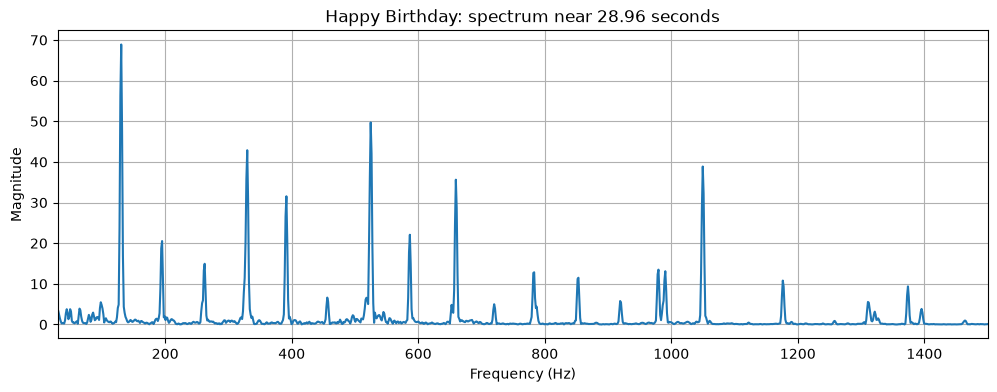

In [13]:

import librosa
import numpy as np
import matplotlib.pyplot as plt

audio_path = project_root / "data" / "processed" / "happy_bday.mp3"

y, sr = librosa.load(audio_path, sr=None, mono=True)

# Inspect a 0.5-second window beginning at the suspicious note onset.
start_time = 28.96
end_time = 29.46

segment = y[int(start_time * sr):int(end_time * sr)]

# Compute the frequency spectrum.
n_fft = 2 ** 15
spectrum = np.abs(np.fft.rfft(segment * np.hanning(len(segment)), n=n_fft))
frequencies = np.fft.rfftfreq(n_fft, d=1 / sr)

plt.figure(figsize=(12, 4))
plt.plot(frequencies, spectrum)
plt.xlim(30, 1500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Happy Birthday: spectrum near 28.96 seconds")
plt.grid(True)
plt.show()


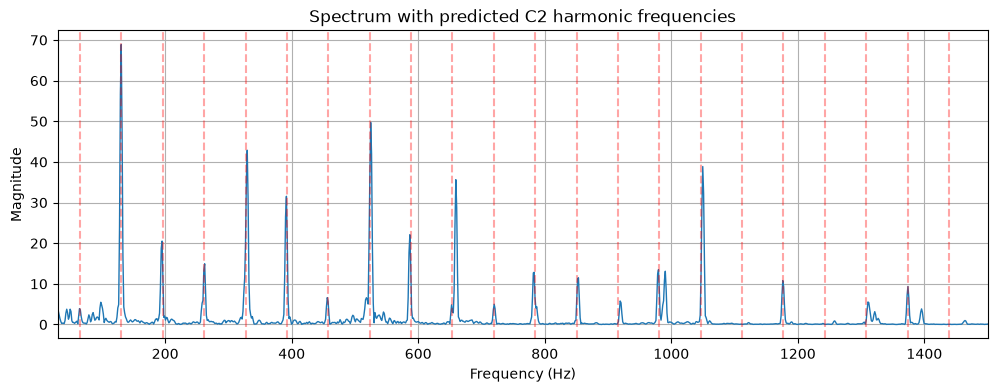

In [14]:

import matplotlib.pyplot as plt
import numpy as np

fundamental = librosa.midi_to_hz(36)  # C2, MIDI 36
harmonics = np.arange(1, 23) * fundamental

plt.figure(figsize=(12, 4))
plt.plot(frequencies, spectrum, linewidth=1)
for i, freq in enumerate(harmonics, start=1):
    if freq <= 1500:
        plt.axvline(
            freq,
            color="red",
            alpha=0.35,
            linestyle="--"
        )
plt.xlim(30, 1500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Spectrum with predicted C2 harmonic frequencies")
plt.grid(True)
plt.show()


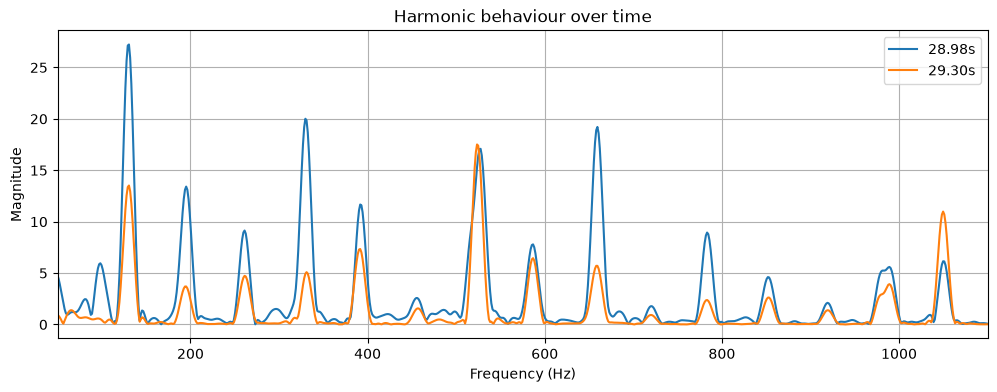

In [15]:

# Compare the start of the suspicious cluster with a later moment.
# Reuse y, sr, and the existing librosa/numpy/matplotlib imports.

def plot_spectrum_at(t, duration=0.15):
    start = int(t * sr)
    segment = y[start:start + int(duration * sr)]
    n_fft = 2 ** 15

    windowed = segment * np.hanning(len(segment))
    spec = np.abs(np.fft.rfft(windowed, n=n_fft))
    freqs = np.fft.rfftfreq(n_fft, d=1 / sr)

    plt.plot(freqs, spec, label=f"{t:.2f}s")

plt.figure(figsize=(12, 4))
plot_spectrum_at(28.98)
plot_spectrum_at(29.30)
plt.xlim(50, 1100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Harmonic behaviour over time")
plt.legend()
plt.grid(True)
plt.show()


In [16]:
prediction_path = (project_root/'data'/'processed'/'piano_sample_20s.mid')
reference_path = (project_root/'data'/'raw'/'maestro'/'piano_sample.midi')

predictions = benchmark.midi_to_notes(prediction_path)
ground_truth = benchmark.midi_to_notes(reference_path)

predictions = [n for n in predictions if n['onset']<20.0]
ground_truth = [n for n in ground_truth if n['onset']<20.0]

results = evaluate_notes(ground_truth, predictions)

print('Prediction file: ',prediction_path)
print('Reference file: ', reference_path)
print('Predicted notes: ',len(predictions))
print('Reference notes: ',len(ground_truth))
print('\nStrict evaluation: ')
for key,value in results.items():
    if key!='matches':
        print(f'{key}: {value}')

Prediction file:  c:\Users\Deep\Desktop\Deep\Piano2MIDI\piano2midi\data\processed\piano_sample_20s.mid
Reference file:  c:\Users\Deep\Desktop\Deep\Piano2MIDI\piano2midi\data\raw\maestro\piano_sample.midi
Predicted notes:  95
Reference notes:  97

Strict evaluation: 
TP: 76
FP: 19
FN: 21
precision: 0.8
recall: 0.7835051546391752
F1: 0.7916666666666666


In [17]:
audio_dir = project_root / "data" / "raw" / "maestro"

audio_extensions = {".wav", ".mp3", ".flac", ".ogg"}
midi_extensions = {".mid", ".midi"}

audio_files = sorted(
    p for p in audio_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in audio_extensions
)

midi_files = sorted(
    p for p in audio_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in midi_extensions
)

print("MAESTRO data inventory")
print("Audio files:", len(audio_files))
print("MIDI files:", len(midi_files))

print("\nAudio examples:")
for path in audio_files[:10]:
    print(path.relative_to(project_root))

print("\nMIDI examples:")
for path in midi_files[:10]:
    print(path.relative_to(project_root))


MAESTRO data inventory
Audio files: 1
MIDI files: 1

Audio examples:
data\raw\maestro\piano_sample.mp3

MIDI examples:
data\raw\maestro\piano_sample.midi


In [20]:

from piano2midi.evaluation.metrics import evaluate_notes

prediction_path = (
    project_root / "data" / "processed" / "piano_sample_20s.mid"
)
reference_path = (
    project_root / "data" / "raw" / "maestro" / "piano_sample.midi"
)

predictions = benchmark.midi_to_notes(prediction_path)
ground_truth = benchmark.midi_to_notes(reference_path)

# Keep the same 20-second excerpt boundary.
predictions = [n for n in predictions if n["onset"] < 20.0]
ground_truth = [n for n in ground_truth if n["onset"] < 20.0]

results = evaluate_notes(ground_truth, predictions)

print("Predictions:", len(predictions))
print("Reference notes:", len(ground_truth))
print("\nStrict evaluation:")

for key, value in results.items():
    print(f"{key}: {value}")


Predictions: 95
Reference notes: 97

Strict evaluation:
TP: 76
FP: 19
FN: 21
precision: 0.8
recall: 0.7835051546391752
F1: 0.7916666666666666


In [21]:

# Phase 6, Step 2 — Reconstruct evaluator matches

matched_reference_indices = set()
matched_prediction_indices = set()

# Reproduce evaluate_notes()'s greedy matching order exactly.
for ref_idx, true_note in enumerate(ground_truth):
    for pred_idx, predicted_note in enumerate(predictions):
        if pred_idx in matched_prediction_indices:
            continue

        if notes_match(
            true_note,
            predicted_note,
            onset_tolerance=0.05,
            offset_tolerance=0.05,
        ):
            matched_reference_indices.add(ref_idx)
            matched_prediction_indices.add(pred_idx)
            break

# Verify reconstructed counts against the established baseline.
TP = len(matched_prediction_indices)
FP = len(predictions) - TP
FN = len(ground_truth) - len(matched_reference_indices)

print(f"Predictions: {len(predictions)}")
print(f"Reference notes: {len(ground_truth)}")
print(f"TP: {TP}")
print(f"FP: {FP}")
print(f"FN: {FN}")

assert (TP, FP, FN) == (76, 19, 21), (
    "Greedy matching does not reproduce the established baseline."
)

# Label each prediction: 0 = matched, 1 = unmatched / false positive.
prediction_labels = [
    0 if idx in matched_prediction_indices else 1
    for idx in range(len(predictions))
]

print(f"Matched prediction indices: {len(matched_prediction_indices)}")
print(f"Label 0 (matched): {prediction_labels.count(0)}")
print(f"Label 1 (false positive): {prediction_labels.count(1)}")
print("Matching reconstruction verified.")


Predictions: 95
Reference notes: 97
TP: 76
FP: 19
FN: 21
Matched prediction indices: 76
Label 0 (matched): 76
Label 1 (false positive): 19
Matching reconstruction verified.


In [22]:

import csv

from pathlib import Path

dataset_path = (
    project_root / "data" / "processed" / "ghost_note_labels.csv"
)

# Inspect available note fields before building rows.
print("Available prediction fields:", sorted(predictions[0].keys()))

fieldnames = [
    "piece_id",
    "prediction_index",
    "pitch",
    "onset",
    "offset",
    "duration",
    "velocity",
    "label",
]

rows = []

for idx, note in enumerate(predictions):
    rows.append({
        "piece_id": "piano_sample_20s",
        "prediction_index": idx,
        "pitch": note["pitch"],
        "onset": note["onset"],
        "offset": note["offset"],
        "duration": note["offset"] - note["onset"],
        "velocity": note.get("velocity", ""),
        "label": prediction_labels[idx],
    })

dataset_path.parent.mkdir(parents=True, exist_ok=True)

with dataset_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print("\nSaved:", dataset_path)
print("Rows:", len(rows))
print("Correct predictions:", sum(r["label"] == 0 for r in rows))
print("False positives:", sum(r["label"] == 1 for r in rows))


Available prediction fields: ['offset', 'onset', 'pitch']

Saved: c:\Users\Deep\Desktop\Deep\Piano2MIDI\piano2midi\data\processed\ghost_note_labels.csv
Rows: 95
Correct predictions: 76
False positives: 19


In [23]:

from piano2midi.evaluation.metrics import notes_match

def label_predictions(
    predictions,
    ground_truth,
    piece_id,
    onset_tolerance=0.05,
    offset_tolerance=0.05,
):
    """Label each predicted note using the existing greedy matching rules."""
    matched_reference_indices = set()
    matched_prediction_indices = set()

    for ref_idx, true_note in enumerate(ground_truth):
        for pred_idx, predicted_note in enumerate(predictions):
            if pred_idx in matched_prediction_indices:
                continue

            if notes_match(
                true_note,
                predicted_note,
                onset_tolerance=onset_tolerance,
                offset_tolerance=offset_tolerance,
            ):
                matched_reference_indices.add(ref_idx)
                matched_prediction_indices.add(pred_idx)
                break

    rows = []

    for idx, note in enumerate(predictions):
        rows.append({
            "piece_id": piece_id,
            "prediction_index": idx,
            "pitch": note["pitch"],
            "onset": note["onset"],
            "offset": note["offset"],
            "duration": note["offset"] - note["onset"],
            "label": 0 if idx in matched_prediction_indices else 1,
        })

    counts = {
        "predictions": len(predictions),
        "reference_notes": len(ground_truth),
        "TP": len(matched_prediction_indices),
        "FP": len(predictions) - len(matched_prediction_indices),
        "FN": len(ground_truth) - len(matched_reference_indices),
    }

    return rows, counts


In [24]:

labelled_rows, label_counts = label_predictions(
    predictions=predictions,
    ground_truth=ground_truth,
    piece_id="piano_sample_20s",
)

print("Label counts:")
for key, value in label_counts.items():
    print(f"{key}: {value}")

print("\nFirst five labelled rows:")
for row in labelled_rows[:5]:
    print(row)

assert (
    label_counts["TP"],
    label_counts["FP"],
    label_counts["FN"],
) == (76, 19, 21)

assert len(labelled_rows) == 95
assert sum(row["label"] == 0 for row in labelled_rows) == 76
assert sum(row["label"] == 1 for row in labelled_rows) == 19

print("\nLabel pipeline verified.")


Label counts:
predictions: 95
reference_notes: 97
TP: 76
FP: 19
FN: 21

First five labelled rows:
{'piece_id': 'piano_sample_20s', 'prediction_index': 0, 'pitch': 49, 'onset': 1.6296875, 'offset': 2.0765625, 'duration': 0.44687500000000013, 'label': 0}
{'piece_id': 'piano_sample_20s', 'prediction_index': 1, 'pitch': 57, 'onset': 2.0125, 'offset': 2.1927083333333335, 'duration': 0.1802083333333333, 'label': 0}
{'piece_id': 'piano_sample_20s', 'prediction_index': 2, 'pitch': 57, 'onset': 2.3015625, 'offset': 2.519791666666667, 'duration': 0.2182291666666667, 'label': 0}
{'piece_id': 'piano_sample_20s', 'prediction_index': 3, 'pitch': 42, 'onset': 1.0515625, 'offset': 2.5864583333333337, 'duration': 1.5348958333333338, 'label': 1}
{'piece_id': 'piano_sample_20s', 'prediction_index': 4, 'pitch': 49, 'onset': 2.5125, 'offset': 2.7286458333333337, 'duration': 0.21614583333333348, 'label': 0}

Label pipeline verified.


In [25]:

import csv

dataset_path = project_root / "data" / "processed" / "ghost_note_labels.csv"

fields = [
    "piece_id", "prediction_index", "pitch",
    "onset", "offset", "duration", "label"
]

with dataset_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(labelled_rows)

print(f"Saved {len(labelled_rows)} labelled notes to {dataset_path.name}")


Saved 95 labelled notes to ghost_note_labels.csv
